In [ ]:
from pathlib import Path

# Locate the archive from the repository root or this notebook's directory.
def _find_archive_root():
    for directory in (Path.cwd(), *Path.cwd().parents):
        for candidate in (directory, directory / "M0" / "training" / "benchmark_archive"):
            if (candidate / "inputs" / "original_m0_tm.csv").is_file():
                return candidate
    raise FileNotFoundError("Run this notebook from the repository or benchmark_archive directory.")

ARCHIVE_DIR = _find_archive_root()
ARCHIVE_INPUT_DIR = ARCHIVE_DIR / "inputs"
ARCHIVE_OUTPUT_DIR = ARCHIVE_DIR / "notebook_outputs"
ARCHIVE_OUTPUT_DIR.mkdir(exist_ok=True)


[I 2026-03-04 15:24:31,197] A new study created in memory with name: no-name-f8d7d8d0-4fea-45eb-99b1-d1049d675280
d:\anaconda3\Lib\site-packages\xgboost\sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(
d:\anaconda3\Lib\site-packages\xgboost\sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(
d:\anaconda3\Lib\site-packages\xgboost\sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(
d:\anaconda3\Lib\site-packages\xgboost\sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better com


✅ Best parameters: {'n_estimators': 1099, 'learning_rate': 0.05378095699103055, 'max_depth': 5, 'min_child_weight': 6, 'subsample': 0.7686947514833556, 'colsample_bytree': 0.794355102219942, 'gamma': 0.6280357539235603, 'reg_lambda': 19.568440232105065, 'reg_alpha': 8.093037123423496}
✅ Best CV R²: 0.8678

📊 Train RMSE: 2.27, R²: 0.9812
📊 Test RMSE: 4.05, R²: 0.9367


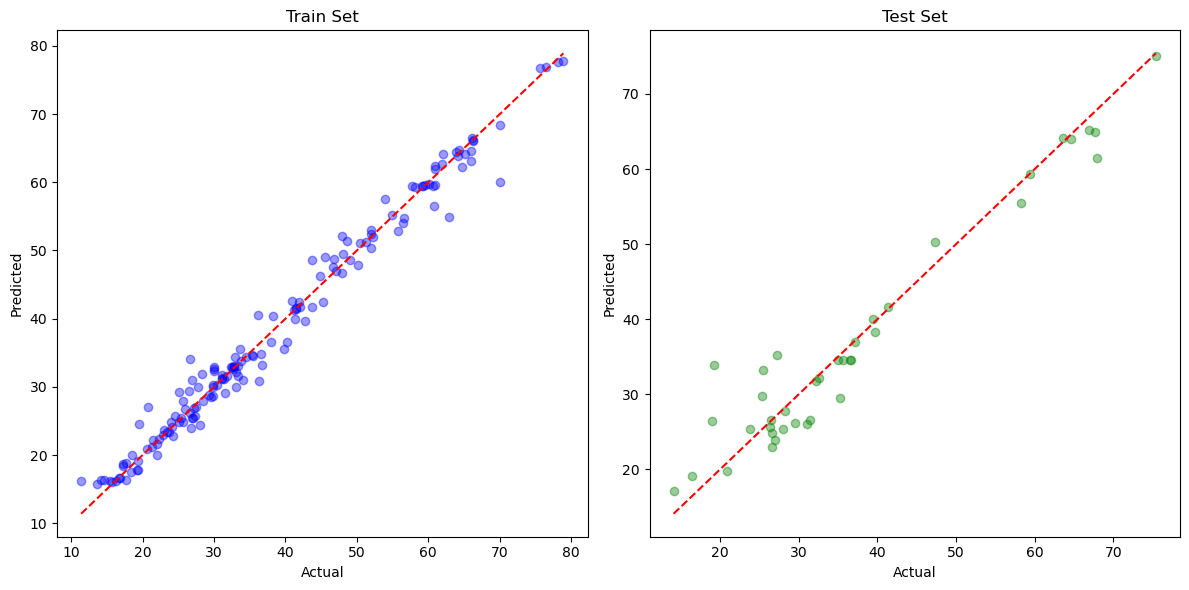

In [2]:
import pandas as pd 
import numpy as np
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb
import optuna
import matplotlib.pyplot as plt
import joblib

# =======================
# Step 1: Read a single dataset and split into training/test sets.
# =======================
# Read one complete dataset rather than separate train_data.csv and test_data.csv files.
data_df = pd.read_csv(str(ARCHIVE_INPUT_DIR / "original_m0_tm.csv"))

# Step 2: Select features and targets: omit the first column and use the last column as the target.
X_df = data_df.iloc[:, 1:-1]
y = data_df.iloc[:, -1]

# Step 3: One-hot encode features without standardization.
# Encode all features before splitting to align the train/test columns.
X_df = pd.get_dummies(X_df, drop_first=True).apply(pd.to_numeric)

# Use train_test_split to split the full dataset (8:2, controlled by test_size).
X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_df, y, test_size=0.2, random_state=42
)

# Retain the original test-column alignment step; it is a no-op after joint encoding.
X_test_df = X_test_df.reindex(columns=X_train_df.columns, fill_value=0)

# Convert to a NumPy array (float32).
X_train = X_train_df.values.astype(np.float32)
X_test = X_test_df.values.astype(np.float32)
y_train = y_train.values.astype(np.float32)
y_test = y_test.values.astype(np.float32)

# =======================
# Step 4: Define the Optuna optimization objective.
# =======================
def optimize(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 900, 1800),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.06),
        'max_depth': trial.suggest_int('max_depth', 4, 6),
        'min_child_weight': trial.suggest_int('min_child_weight', 2, 10),
        'subsample': trial.suggest_float('subsample', 0.75, 0.95),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.60, 0.82),
        'gamma': trial.suggest_float('gamma', 0.2, 1.5),
        'reg_lambda': trial.suggest_float('reg_lambda', 15, 90),
        'reg_alpha': trial.suggest_float('reg_alpha', 8, 45),
        'objective': 'reg:squarederror',
        'random_state': 42
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = []

    for train_idx, valid_idx in kf.split(X_train):
        X_t, X_v = X_train[train_idx], X_train[valid_idx]
        y_t, y_v = y_train[train_idx], y_train[valid_idx]

        model = xgb.XGBRegressor(**params)
        model.fit(X_t, y_t, eval_set=[(X_v, y_v)], early_stopping_rounds=100, verbose=False)

        y_pred = model.predict(X_v)
        score = r2_score(y_v, y_pred)
        scores.append(score)

    return np.mean(scores)

# Step 5: Run hyperparameter tuning.
study = optuna.create_study(direction='maximize')
study.optimize(optimize, n_trials=300)

print("\n✅ Best parameters:", study.best_params)
print(f"✅ Best CV R²: {study.best_value:.4f}")

# Step 6: Train the final model with the best parameters.
# Fix objective and random_state for the final model:
best_params = study.best_params.copy()
best_params.update({'objective': 'reg:squarederror', 'random_state': 42})
best_model = xgb.XGBRegressor(**best_params)

best_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], early_stopping_rounds=100, verbose=False)

# Step 7: Save the model.
joblib.dump(best_model, "best_model_xgb_optuna_kfold.pkl")

# Step 8: Evaluate the model.
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
r2_train = r2_score(y_train, y_train_pred)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
r2_test = r2_score(y_test, y_test_pred)

print(f"\n📊 Train RMSE: {rmse_train:.2f}, R²: {r2_train:.4f}")
print(f"📊 Test RMSE: {rmse_test:.2f}, R²: {r2_test:.4f}")

# Step 9: Visualize results.
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.scatter(y_train, y_train_pred, alpha=0.4, color='blue')
plt.plot([min(y_train), max(y_train)], [min(y_train), max(y_train)], 'r--')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Train Set")

plt.subplot(1, 2, 2)
plt.scatter(y_test, y_test_pred, alpha=0.4, color='green')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Test Set")

plt.tight_layout()
plt.savefig("optuna_xgb_kfold_result.png", dpi=300)
plt.show()


Total samples: 193
Mass-fraction columns: ['ID1', 'ID2', 'ID3']
Target column: Melting temperature (Tm, ℃)


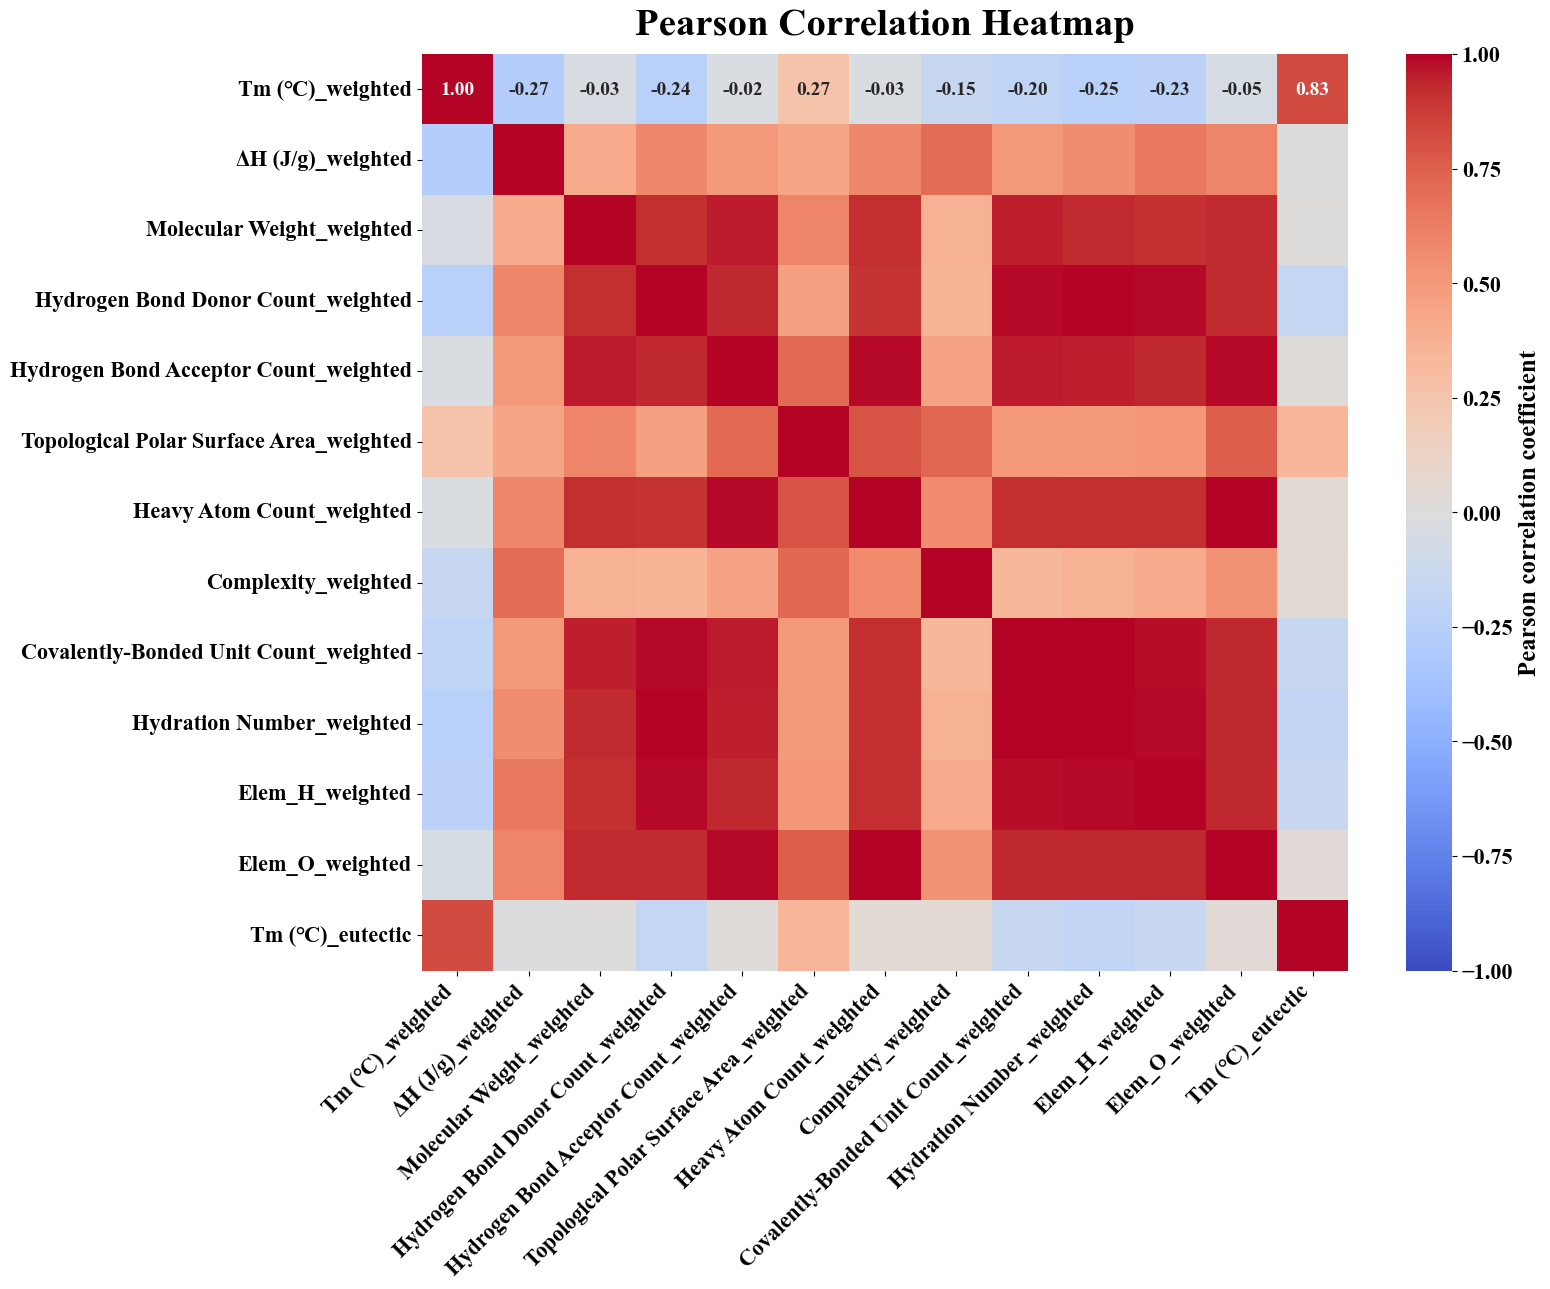

Saved: notebook_outputs/Tm_weighted_pearson_heatmap_all_samples.png


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# =====================================
# Melting-temperature Pearson correlation heatmap (all samples).
# weighted = ID1*salt1_feature + ID2*salt2_feature + ID3*salt3_feature
# White background, Times New Roman, and large bold text.
# =====================================
file_path = str(ARCHIVE_INPUT_DIR / "original_m0_tm.csv")
df = pd.read_csv(file_path)

# Global style: Times New Roman and large bold text.
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titlesize"] = 28
plt.rcParams["axes.labelsize"] = 20
plt.rcParams["xtick.labelsize"] = 16
plt.rcParams["ytick.labelsize"] = 16

# Fixed CSV column structure:
# [0] salt name | [1:13] component-1 features | [13:25] component-2 features | [25:37] component-3 features
# [37:40] ID1/ID2/ID3 | [40] melting-temperature target
ratio_cols = [df.columns[37], df.columns[38], df.columns[39]]
target_col = df.columns[40]

feature_names = [
    "Tm (℃)",
    "ΔH (J/g)",
    "Molecular Weight",
    "Hydrogen Bond Donor Count",
    "Hydrogen Bond Acceptor Count",
    "Topological Polar Surface Area",
    "Heavy Atom Count",
    "Complexity",
    "Covalently-Bonded Unit Count",
    "Hydration Number",
    "Elem_H",
    "Elem_O",
]

# Use all samples without filtering on ID3.
all_df = df.copy()
for c in all_df.columns:
    all_df[c] = pd.to_numeric(all_df[c], errors="ignore")

# Generate mass-fraction-weighted features.
r1 = pd.to_numeric(all_df[ratio_cols[0]], errors="coerce")
r2 = pd.to_numeric(all_df[ratio_cols[1]], errors="coerce")
r3 = pd.to_numeric(all_df[ratio_cols[2]], errors="coerce")

weighted_df = pd.DataFrame(index=all_df.index)
for i, feat in enumerate(feature_names):
    f1 = pd.to_numeric(all_df.iloc[:, 1 + i], errors="coerce")
    f2 = pd.to_numeric(all_df.iloc[:, 13 + i], errors="coerce")
    f3 = pd.to_numeric(all_df.iloc[:, 25 + i], errors="coerce")

    weighted_df[f"{feat}_weighted"] = r1 * f1 + r2 * f2 + r3 * f3

weighted_df["Tm (℃)_eutectic"] = pd.to_numeric(all_df[target_col], errors="coerce")
weighted_df = weighted_df.dropna(axis=0, how="any")

print(f"Total samples: {weighted_df.shape[0]}")
print("Mass-fraction columns:", ratio_cols)
print("Target column:", target_col)

# Pearson correlation matrix.
corr = weighted_df.corr(method="pearson")

# Annotate only the first row, following the example plot style.
annot_mat = np.full(corr.shape, "", dtype=object)
annot_mat[0, :] = [f"{v:.2f}" for v in corr.iloc[0, :].values]

# White plotting canvas.
fig, ax = plt.subplots(figsize=(16, 13))

hm = sns.heatmap(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    annot=annot_mat,
    fmt="",
    annot_kws={"size": 14, "family": "Times New Roman", "weight": "bold"},
    square=False,
    cbar_kws={"label": "Pearson correlation coefficient"},
    ax=ax,
)

ax.set_title("Pearson Correlation Heatmap", fontsize=28, pad=14, fontweight="bold")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

# Use bold axis labels.
for t in ax.get_xticklabels():
    t.set_fontweight("bold")
for t in ax.get_yticklabels():
    t.set_fontweight("bold")

# Use bold colorbar labels.
cbar = hm.collections[0].colorbar
cbar.ax.tick_params(labelsize=16)
for t in cbar.ax.get_yticklabels():
    t.set_fontweight("bold")
cbar.set_label("Pearson correlation coefficient", size=18, weight="bold")

plt.tight_layout()
out_png = str(ARCHIVE_OUTPUT_DIR / "Tm_weighted_pearson_heatmap_all_samples.png")
plt.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", out_png)

In [ ]:
import numpy as np
import pandas as pd
import xgboost as xgb
import joblib
from sklearn.metrics import mean_squared_error, r2_score

# =======================
# Refit the final melting-temperature model on all data with fixed best hyperparameters.
# =======================

# 1) Read all data from the archived input, with a current-directory fallback.
def _load_data():
    candidates = [
        str(ARCHIVE_INPUT_DIR / "original_m0_tm.csv"),
    ]
    for p in candidates:
        try:
            return pd.read_csv(p), p
        except Exception:
            pass
    raise FileNotFoundError("original_m0_tm.csv was not found; check the input path.")


data_df, used_path = _load_data()
print(f"Input data file: {used_path}")
print(f"Total samples: {len(data_df)}")

# 2) Select features and targets using the original column convention.
X_df = data_df.iloc[:, 1:-1].copy()
y = pd.to_numeric(data_df.iloc[:, -1], errors="coerce")

# Drop rows with missing targets.
valid_mask = y.notna()
X_df = X_df.loc[valid_mask]
y = y.loc[valid_mask]

# 3) One-hot encode the complete feature table.
X_all_df = pd.get_dummies(X_df, drop_first=True).apply(pd.to_numeric)
X_all = X_all_df.values.astype(np.float32)
y_all = y.values.astype(np.float32)

print(f"Encoded feature dimensions: {X_all.shape}")

# 4) Use the fixed best hyperparameters.
best_params = {
    "n_estimators": 1099,
    "learning_rate": 0.05378095699103055,
    "max_depth": 5,
    "min_child_weight": 6,
    "subsample": 0.7686947514833556,
    "colsample_bytree": 0.794355102219942,
    "gamma": 0.6280357539235603,
    "reg_lambda": 19.568440232105065,
    "reg_alpha": 8.093037123423496,
    "objective": "reg:squarederror",
    "random_state": 42,
}

# 5) Refit on all data.
final_model = xgb.XGBRegressor(**best_params)
final_model.fit(X_all, y_all, verbose=False)

# 6) Report full-data training-fit metrics for reference.
y_all_pred = final_model.predict(X_all)
rmse_all = np.sqrt(mean_squared_error(y_all, y_all_pred))
r2_all = r2_score(y_all, y_all_pred)
print(f"📊 Full-data RMSE: {rmse_all:.4f}, R²: {r2_all:.4f}")

# 7) Save the model and training column names; prediction columns must be aligned.
joblib.dump(final_model, "best_model_xgb_full_data.pkl")

print("✅ Saved: best_model_xgb_full_data.pkl")

Input data file: inputs/original_m0_tm.csv
Total samples: 186
Encoded feature dimensions: (186, 39)
📊 Full-data RMSE: 1.8386, R²: 0.9878
✅ Saved: best_model_xgb_full_data.pkl
